In [ ]:
# This Python 3 environment comes with many helpful analytics libraries installed
# It is defined by the kaggle/python Docker image: https://github.com/kaggle/docker-python
# For example, here's several helpful packages to load

import numpy as np # linear algebra
import pandas as pd # data processing, CSV file I/O (e.g. pd.read_csv)

# Input data files are available in the read-only "../input/" directory
# For example, running this (by clicking run or pressing Shift+Enter) will list all files under the input directory

import os
for dirname, _, filenames in os.walk('/kaggle/input'):
    for filename in filenames:
        print(os.path.join(dirname, filename))

# You can write up to 20GB to the current directory (/kaggle/working/) that gets preserved as output when you create a version using "Save & Run All" 
# You can also write temporary files to /kaggle/temp/, but they won't be saved outside of the current session

# Use the kagglehub client library to attach Kaggle resources like competitions, datasets, and models to your session
# Learn more about kagglehub: https://github.com/Kaggle/kagglehub/blob/main/README.md

import kagglehub
# kagglehub.dataset_download('<owner>/<dataset-slug>')

In [ ]:

import os

print("Attached datasets:")
print(os.listdir("/kaggle/input"))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    print("Folder:", root)
    print("Files:", files[:10])
    print("--------------------")

In [ ]:

import os

base_path = "/kaggle/input/datasets/kacpergregorowiczz/skin-cancer-mnist-ham10000"

print("Checking dataset...")

total_images = 0

for root, dirs, files in os.walk(base_path):
    images = [
        f for f in files
        if f.lower().endswith((".jpg", ".jpeg", ".png"))
    ]

    if images:
        print(root, ":", len(images), "images")
        total_images += len(images)

print("\nTotal image files:", total_images)

print("\nCSV metadata files:")
for root, dirs, files in os.walk(base_path):
    for file in files:
        if file.lower().endswith(".csv"):
            print(os.path.join(root, file))


In [ ]:

import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "HAM10000_metadata.csv" in files:
        print("SUCCESS! Correct dataset found!")
        print("Location:", root)


In [ ]:

import pandas as pd

# Correct HAM10000 dataset location
dataset_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

# Read metadata
df = pd.read_csv(
    dataset_path + "/HAM10000_metadata.csv"
)

# Display dataset information
print("Total metadata records:", len(df))

print("\nFirst 5 rows:")
display(df.head())

print("\nSeven skin lesion classes:")
print(df["dx"].value_counts())

print("\nMissing values:")
print(df.isnull().sum())


In [ ]:

import matplotlib.pyplot as plt
import seaborn as sns

# Count images in each class
class_counts = df["dx"].value_counts()

# Create bar chart
plt.figure(figsize=(10, 5))

sns.barplot(
    x=class_counts.index,
    y=class_counts.values,
    hue=class_counts.index,
    palette="viridis",
    legend=False
)

plt.title("HAM10000 Skin Lesion Class Distribution")
plt.xlabel("Skin Lesion Category")
plt.ylabel("Number of Images")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [ ]:

import os
import glob
import matplotlib.pyplot as plt
from PIL import Image

# Find all HAM10000 image files
image_paths = glob.glob(
    dataset_path + "/**/*.jpg",
    recursive=True
)

# Create image lookup dictionary
image_dict = {
    os.path.splitext(os.path.basename(path))[0]: path
    for path in image_paths
}

print("Image files found:", len(image_paths))

# Display one example from each class
classes = df["dx"].unique()

fig, axes = plt.subplots(1, 7, figsize=(20, 4))

for i, label in enumerate(classes):
    sample = df[df["dx"] == label].iloc[0]
    image_id = sample["image_id"]

    if image_id in image_dict:
        img = Image.open(image_dict[image_id])
        axes[i].imshow(img)
        axes[i].set_title(label)
    else:
        axes[i].set_title(f"{label}\nNot found")

    axes[i].axis("off")

plt.suptitle("HAM10000: Seven Skin Lesion Categories")
plt.tight_layout()
plt.show()


In [ ]:

# Step 9.1: Check lesion IDs

print("Total images:", len(df))

print("Unique lesions:", df["lesion_id"].nunique())

print("Duplicate lesion images:",
      len(df) - df["lesion_id"].nunique())

print("\nMissing lesion IDs:")
print(df["lesion_id"].isnull().sum())

print("\nClasses per lesion:")
print(
    df.groupby("lesion_id")["dx"]
      .nunique()
      .value_counts()
)


In [ ]:

import pandas as pd
from sklearn.model_selection import train_test_split

# Create one record per unique lesion
lesion_df = df.groupby("lesion_id", as_index=False).agg(
    dx=("dx", "first")
)

# Split lesions: 70% train, 30% temporary
train_lesions, temp_lesions = train_test_split(
    lesion_df,
    test_size=0.30,
    random_state=42,
    stratify=lesion_df["dx"]
)

# Split temporary lesions into validation and test
val_lesions, test_lesions = train_test_split(
    temp_lesions,
    test_size=0.50,
    random_state=42,
    stratify=temp_lesions["dx"]
)

# Select all images belonging to each lesion group
train_df = df[
    df["lesion_id"].isin(train_lesions["lesion_id"])
].copy()

val_df = df[
    df["lesion_id"].isin(val_lesions["lesion_id"])
].copy()

test_df = df[
    df["lesion_id"].isin(test_lesions["lesion_id"])
].copy()

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nTotal images:",
      len(train_df) + len(val_df) + len(test_df))

# Check for leakage
train_ids = set(train_df["lesion_id"])
val_ids = set(val_df["lesion_id"])
test_ids = set(test_df["lesion_id"])

assert train_ids.isdisjoint(val_ids)
assert train_ids.isdisjoint(test_ids)
assert val_ids.isdisjoint(test_ids)

assert len(train_df) + len(val_df) + len(test_df) == len(df)

print("\nSUCCESS: No lesion-level data leakage!")


In [ ]:

import os

# Create folder
save_path = "/kaggle/working/splits"
os.makedirs(save_path, exist_ok=True)

# Save CSV files
train_df.to_csv(save_path + "/train.csv", index=False)
val_df.to_csv(save_path + "/val.csv", index=False)
test_df.to_csv(save_path + "/test.csv", index=False)

# Verify saved files
print("Dataset splits saved successfully!")

print("\nSaved files:")
print(os.listdir(save_path))

# Check class distribution in each split
print("\nClass distribution:")
print(pd.DataFrame({
    "Train": train_df["dx"].value_counts(),
    "Validation": val_df["dx"].value_counts(),
    "Test": test_df["dx"].value_counts()
}).fillna(0).astype(int))


In [ ]:

import os

split_dir = "/kaggle/working/splits"

if os.path.exists(split_dir):
    print("SUCCESS! Splits folder found.")
    print("Files:", os.listdir(split_dir))
else:
    print("Splits folder not found.")


In [ ]:

import os

print("Searching for saved CSV files...")

found = []

for root, dirs, files in os.walk("/kaggle"):
    for file in files:
        if file in ["train.csv", "val.csv", "test.csv"]:
            path = os.path.join(root, file)
            found.append(path)
            print("FOUND:", path)

if not found:
    print("No saved split CSV files found.")


In [ ]:

import os

dataset_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

if os.path.exists(dataset_path):
    print("SUCCESS! HAM10000 dataset found.")
    print("Files:", os.listdir(dataset_path)[:15])
else:
    print("Dataset not found. Please attach HAM10000.")


In [ ]:

import pandas as pd
import os

dataset_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

metadata_path = os.path.join(
    dataset_path, "HAM10000_metadata.csv"
)

df = pd.read_csv(metadata_path)

print("Total images:", len(df))
print("Unique lesions:", df["lesion_id"].nunique())
print("\nSeven lesion classes:")
print(df["dx"].value_counts())

print("\nMissing values:")
print(df[["image_id", "lesion_id", "dx"]].isnull().sum())


In [ ]:

import os
import pandas as pd
from sklearn.model_selection import train_test_split

# One class label per lesion
lesions = df.groupby("lesion_id")["dx"].first().reset_index()

# Ensure each lesion has only one diagnosis
assert (df.groupby("lesion_id")["dx"].nunique() == 1).all()

# 70% training lesions, 30% remaining
train_ids, remaining_ids = train_test_split(
    lesions,
    test_size=0.30,
    random_state=42,
    stratify=lesions["dx"]
)

# Divide remaining lesions equally
val_ids, test_ids = train_test_split(
    remaining_ids,
    test_size=0.50,
    random_state=42,
    stratify=remaining_ids["dx"]
)

train_df = df[df["lesion_id"].isin(train_ids["lesion_id"])].copy()
val_df = df[df["lesion_id"].isin(val_ids["lesion_id"])].copy()
test_df = df[df["lesion_id"].isin(test_ids["lesion_id"])].copy()

# Check lesion-level leakage
train_set = set(train_df["lesion_id"])
val_set = set(val_df["lesion_id"])
test_set = set(test_df["lesion_id"])

assert train_set.isdisjoint(val_set)
assert train_set.isdisjoint(test_set)
assert val_set.isdisjoint(test_set)

# Save CSV files
split_dir = "/kaggle/working/splits"
os.makedirs(split_dir, exist_ok=True)

train_df.to_csv(f"{split_dir}/train.csv", index=False)
val_df.to_csv(f"{split_dir}/val.csv", index=False)
test_df.to_csv(f"{split_dir}/test.csv", index=False)

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))
print("Total:", len(train_df) + len(val_df) + len(test_df))
print("SUCCESS: No lesion-level data leakage!")
print("CSV files saved in:", split_dir)


In [ ]:

import pandas as pd
import os

split_dir = "/kaggle/working/splits"

for name in ["train", "val", "test"]:
    path = os.path.join(split_dir, f"{name}.csv")
    data = pd.read_csv(path)

    print(f"{name.upper()} CSV")
    print("Images:", len(data))
    print("Columns:", list(data.columns))
    print("Classes:", data["dx"].nunique())
    print("-" * 35)

print("SUCCESS! All three CSV files loaded.")


In [ ]:

import os

folder = "/kaggle/working/splits"

if os.path.exists(folder):
    print("SUCCESS! Splits folder found.")
    print("Files:", os.listdir(folder))
else:
    print("Splits folder not found.")


In [4]:
import os

image_folder_1 = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1"

image_folder_2 = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2"

print("Folder 1 exists:", os.path.exists(image_folder_1))
print("Folder 2 exists:", os.path.exists(image_folder_2))

Folder 1 exists: True
Folder 2 exists: True


In [ ]:
import os

# Collect available image IDs
image_files = (
    os.listdir(image_folder_1) +
    os.listdir(image_folder_2)
)

available_ids = {
    os.path.splitext(filename)[0]
    for filename in image_files
    if filename.lower().endswith(".jpg")
}

# Compare against metadata
missing_ids = set(df["image_id"]) - available_ids

print("Metadata images:", len(df))
print("Available unique JPG images:", len(available_ids))
print("Missing images:", len(missing_ids))
print("Example missing IDs:", list(missing_ids)[:5])

In [ ]:
from PIL import Image
import os

# Select one image
sample_id = df["image_id"].iloc[0]
filename = sample_id + ".jpg"

# Find the image
path1 = os.path.join(image_folder_1, filename)
path2 = os.path.join(image_folder_2, filename)

image_path = path1 if os.path.exists(path1) else path2

# Open the image
img = Image.open(image_path).convert("RGB")

print("Image ID:", sample_id)
print("Image size:", img.size)
print("Image mode:", img.mode)

display(img)

In [ ]:
from PIL import Image

# Resize the sample image
resized_img = img.resize((224, 224), Image.Resampling.BILINEAR)

print("Original size:", img.size)
print("Resized size:", resized_img.size)

display(resized_img)

In [ ]:
import numpy as np

# Convert resized image to an array
image_array = np.array(resized_img)

# Normalize pixel values to 0-1
normalized_img = image_array.astype("float32") / 255.0

print("Original pixel range:",
      image_array.min(), image_array.max())

print("Normalized pixel range:",
      normalized_img.min(), normalized_img.max())

print("Image shape:", normalized_img.shape)

In [ ]:
from PIL import Image
import matplotlib.pyplot as plt
import os

# Find a sample image from the HAM10000 dataset
base_path = "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000"

image_path = os.path.join(
    base_path,
    "HAM10000_images_part_1",
    "ISIC_0024306.jpg"
)

# Open and resize image
img = Image.open(image_path).convert("RGB")
img = img.resize((224, 224))

# Create augmented images
rotated_img = img.rotate(90)
flipped_img = img.transpose(Image.Transpose.FLIP_LEFT_RIGHT)

# Display results
fig, axes = plt.subplots(1, 3, figsize=(10, 4))

for ax, image, title in zip(
    axes,
    [img, rotated_img, flipped_img],
    ["Original", "Rotated 90°", "Flipped"]
):
    ax.imshow(image)
    ax.set_title(title)
    ax.axis("off")

plt.tight_layout()
plt.show()

In [3]:
import torch
from torchvision import transforms

# Transformations for training images
train_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomVerticalFlip(p=0.5),
    transforms.RandomRotation(20),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

# Transformations for validation and testing images
val_test_transform = transforms.Compose([
    transforms.Resize((224, 224)),
    transforms.ToTensor(),
    transforms.Normalize(
        mean=[0.485, 0.456, 0.406],
        std=[0.229, 0.224, 0.225]
    )
])

print("SUCCESS! PyTorch image transformations created.")

SUCCESS! PyTorch image transformations created.


In [ ]:
import os

split_dir = "/kaggle/working/splits"

for name in ["train.csv", "val.csv", "test.csv"]:
    path = os.path.join(split_dir, name)
    print(name, "exists:", os.path.isfile(path))

In [ ]:
import os

split_dir = "/kaggle/input/ham10000-seven-class-splits"

for name in ["train.csv", "val.csv", "test.csv"]:
    path = os.path.join(split_dir, name)
    print(name, "exists:", os.path.isfile(path))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if all(name in files for name in ["train.csv", "val.csv", "test.csv"]):
        print("CSV folder found:", root)

In [ ]:
import os
import pandas as pd

# Correct Kaggle dataset path
split_dir = "/kaggle/input/datasets/bilkisarajannat/ham10000-seven-class-splits"

# Check all three CSV files
for name in ["train.csv", "val.csv", "test.csv"]:
    path = os.path.join(split_dir, name)
    print(name, "exists:", os.path.isfile(path))

In [ ]:
split_dir = "/kaggle/input/datasets/bilkisarajannat/ham10000-seven-class-splits"

print("CSV folder path restored successfully!")

In [ ]:
import pandas as pd
import os

train_df = pd.read_csv(os.path.join(split_dir, "train.csv"))
val_df = pd.read_csv(os.path.join(split_dir, "val.csv"))
test_df = pd.read_csv(os.path.join(split_dir, "test.csv"))

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("\nSeven skin lesion classes:")
print(sorted(train_df["dx"].unique()))

In [2]:
import os
from PIL import Image
from torch.utils.data import Dataset

# Seven skin lesion classes
class_names = sorted(train_df["dx"].unique())

class_to_idx = {
    name: idx for idx, name in enumerate(class_names)
}

class HAM10000Dataset(Dataset):
    def __init__(self, dataframe, image_dirs, transform=None):
        self.df = dataframe.reset_index(drop=True)
        self.image_dirs = image_dirs
        self.transform = transform

    def __len__(self):
        return len(self.df)

    def __getitem__(self, idx):
        row = self.df.iloc[idx]

        image_name = row["image_id"] + ".jpg"
        label = class_to_idx[row["dx"]]

        image_path = None

        for folder in self.image_dirs:
            candidate = os.path.join(folder, image_name)

            if os.path.isfile(candidate):
                image_path = candidate
                break

        if image_path is None:
            raise FileNotFoundError(image_name)

        with Image.open(image_path) as img:
            image = img.convert("RGB")

        if self.transform:
            image = self.transform(image)

        return image, label

print("SUCCESS! HAM10000 Dataset class created.")
print("Class mapping:", class_to_idx)

SUCCESS! HAM10000 Dataset class created.
Class mapping: {'akiec': 0, 'bcc': 1, 'bkl': 2, 'df': 3, 'mel': 4, 'nv': 5, 'vasc': 6}


In [5]:
# Connect both original HAM10000 image folders
image_dirs = [
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_1",
    "/kaggle/input/datasets/kmader/skin-cancer-mnist-ham10000/HAM10000_images_part_2"
]

# Create training dataset
train_dataset = HAM10000Dataset(
    dataframe=train_df,
    image_dirs=image_dirs,
    transform=train_transform
)

# Test one training image
image, label = train_dataset[0]

print("Training dataset size:", len(train_dataset))
print("Image tensor shape:", image.shape)
print("Numerical label:", label)
print("Class name:", class_names[label])

Training dataset size: 6981
Image tensor shape: torch.Size([3, 224, 224])
Numerical label: 2
Class name: bkl


In [6]:
# Create validation dataset
val_dataset = HAM10000Dataset(
    dataframe=val_df,
    image_dirs=image_dirs,
    transform=val_test_transform
)

# Create testing dataset
test_dataset = HAM10000Dataset(
    dataframe=test_df,
    image_dirs=image_dirs,
    transform=val_test_transform
)

print("Training images:", len(train_dataset))
print("Validation images:", len(val_dataset))
print("Testing images:", len(test_dataset))

# Check one validation and testing image
val_image, val_label = val_dataset[0]
test_image, test_label = test_dataset[0]

print("Validation image shape:", val_image.shape)
print("Testing image shape:", test_image.shape)

print("SUCCESS! All three datasets are ready.")

Training images: 6981
Validation images: 1532
Testing images: 1502
Validation image shape: torch.Size([3, 224, 224])
Testing image shape: torch.Size([3, 224, 224])
SUCCESS! All three datasets are ready.


In [8]:
from torch.utils.data import DataLoader

# Create DataLoaders
train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    shuffle=True,
    num_workers=2
)

val_loader = DataLoader(
    val_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

test_loader = DataLoader(
    test_dataset,
    batch_size=16,
    shuffle=False,
    num_workers=2
)

print("Training batches:", len(train_loader))
print("Validation batches:", len(val_loader))
print("Testing batches:", len(test_loader))

print("SUCCESS! All DataLoaders created.")

Training batches: 437
Validation batches: 96
Testing batches: 94
SUCCESS! All DataLoaders created.


In [ ]:
# Load one batch of training images
images, labels = next(iter(train_loader))

print("Batch image shape:", images.shape)
print("Batch label shape:", labels.shape)
print("Labels:", labels.tolist())

print("SUCCESS! Training batch loaded correctly.")

In [ ]:
import torch

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled.")

In [ ]:
print("Training dataset:", len(train_dataset))
print("Validation dataset:", len(val_dataset))
print("Testing dataset:", len(test_dataset))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if "HAM10000_images_part_1" in dirs:
        print("Folder 1:", os.path.join(root, "HAM10000_images_part_1"))

    if "HAM10000_images_part_2" in dirs:
        print("Folder 2:", os.path.join(root, "HAM10000_images_part_2"))

In [ ]:
import torch

print("GPU available:", torch.cuda.is_available())

if torch.cuda.is_available():
    print("GPU name:", torch.cuda.get_device_name(0))

In [ ]:
import os

for root, dirs, files in os.walk("/kaggle/input"):
    if all(name in files for name in ["train.csv", "val.csv", "test.csv"]):
        print("CSV folder found:", root)

In [1]:
import os
import pandas as pd

split_dir = "/kaggle/input/datasets/bilkisarajannat/ham10000-seven-class-splits-backup"

train_df = pd.read_csv(os.path.join(split_dir, "train.csv"))
val_df = pd.read_csv(os.path.join(split_dir, "val.csv"))
test_df = pd.read_csv(os.path.join(split_dir, "test.csv"))

print("Training images:", len(train_df))
print("Validation images:", len(val_df))
print("Testing images:", len(test_df))

print("SUCCESS! All CSV datasets restored.")

Training images: 6981
Validation images: 1532
Testing images: 1502
SUCCESS! All CSV datasets restored.


In [9]:
import torch

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")

print("Device:", device)

if torch.cuda.is_available():
    print("GPU:", torch.cuda.get_device_name(0))
else:
    print("GPU is not enabled.")

Device: cuda
GPU: Tesla T4


In [11]:
import torch
import torch.nn as nn
from torchvision import models

class HybridCNNViT(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        # CNN feature extractor
        self.cnn = models.resnet18(weights=None)

        # Remove the original classification layer
        self.cnn.fc = nn.Identity()

        # Convert CNN features into Transformer tokens
        self.embedding = nn.Linear(512, 256)

        # Vision Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256,
            nhead=8,
            dim_feedforward=512,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2,
            enable_nested_tensor=False
        )

        # Final classification layer
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):
        features = self.cnn(x)

        tokens = self.embedding(features)
        tokens = tokens.unsqueeze(1)

        transformed = self.transformer(tokens)

        output = self.classifier(transformed[:, 0, :])

        return output


model = HybridCNNViT(num_classes=7).to(device)

print("SUCCESS! Hybrid CNN + Transformer model created.")
print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

SUCCESS! Hybrid CNN + Transformer model created.
Device: cuda
Total parameters: 12363847


In [12]:
import torch
import torch.nn as nn
from torchvision import models

class ImprovedHybridCNNViT(nn.Module):
    def __init__(self, num_classes=7):
        super().__init__()

        # ResNet18 CNN backbone
        resnet = models.resnet18(weights=None)

        # Remove average pooling and classification layers
        self.cnn = nn.Sequential(*list(resnet.children())[:-2])

        # Convert CNN features to Transformer embeddings
        self.embedding = nn.Linear(512, 256)

        # Learnable positional embeddings for 49 image regions
        self.pos_embedding = nn.Parameter(
            torch.zeros(1, 49, 256)
        )

        # Transformer encoder
        encoder_layer = nn.TransformerEncoderLayer(
            d_model=256,
            nhead=8,
            dim_feedforward=512,
            dropout=0.1,
            batch_first=True
        )

        self.transformer = nn.TransformerEncoder(
            encoder_layer,
            num_layers=2
        )

        # Seven-class classifier
        self.classifier = nn.Linear(256, num_classes)

    def forward(self, x):

        # CNN features: [batch, 512, 7, 7]
        features = self.cnn(x)

        # Create 49 spatial tokens
        tokens = features.flatten(2).transpose(1, 2)

        # Project tokens to 256 dimensions
        tokens = self.embedding(tokens)

        # Add positional information
        tokens = tokens + self.pos_embedding

        # Transformer processes relationships between regions
        tokens = self.transformer(tokens)

        # Average the 49 tokens
        pooled = tokens.mean(dim=1)

        # Predict seven lesion classes
        output = self.classifier(pooled)

        return output


model = ImprovedHybridCNNViT(num_classes=7).to(device)

print("SUCCESS! Improved Hybrid CNN + ViT model created.")
print("Device:", device)
print("Total parameters:", sum(p.numel() for p in model.parameters()))

SUCCESS! Improved Hybrid CNN + ViT model created.
Device: cuda
Total parameters: 12376391


In [13]:
import torch

# Put the model in evaluation mode
model.eval()

# Get one batch of training images
images, labels = next(iter(train_loader))

# Move images to GPU
images = images.to(device)

# Test the model without calculating gradients
with torch.no_grad():
    outputs = model(images)

print("Input image shape:", images.shape)
print("Model output shape:", outputs.shape)
print("SUCCESS! Hybrid CNN + ViT forward pass completed.")

Input image shape: torch.Size([16, 3, 224, 224])
Model output shape: torch.Size([16, 7])
SUCCESS! Hybrid CNN + ViT forward pass completed.


In [14]:
import torch
import torch.nn as nn
import torch.optim as optim

# Loss function for seven-class classification
criterion = nn.CrossEntropyLoss()

# AdamW optimizer
optimizer = optim.AdamW(
    model.parameters(),
    lr=0.0001,
    weight_decay=0.01
)

# Number of training epochs
num_epochs = 10

print("SUCCESS! Training configuration created.")
print("Loss function:", criterion)
print("Optimizer: AdamW")
print("Learning rate: 0.0001")
print("Epochs:", num_epochs)
print("Device:", device)

SUCCESS! Training configuration created.
Loss function: CrossEntropyLoss()
Optimizer: AdamW
Learning rate: 0.0001
Epochs: 10
Device: cuda


In [15]:
import torch
import time
import os

# Train for one epoch first
model.train()

running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

print("Starting Hybrid CNN + ViT training...")

for batch_idx, (images, labels) in enumerate(train_loader):

    images = images.to(device)
    labels = labels.to(device)

    # Clear previous gradients
    optimizer.zero_grad()

    # Forward pass
    outputs = model(images)

    # Calculate loss
    loss = criterion(outputs, labels)

    # Backpropagation
    loss.backward()

    # Update model parameters
    optimizer.step()

    # Calculate training statistics
    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)
    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    # Show progress every 50 batches
    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(train_loader)} "
            f"| Loss: {running_loss / total:.4f} "
            f"| Accuracy: {100 * correct / total:.2f}%",
            flush=True
        )

epoch_loss = running_loss / total
epoch_accuracy = 100 * correct / total

print("\nTraining epoch completed!")
print(f"Training Loss: {epoch_loss:.4f}")
print(f"Training Accuracy: {epoch_accuracy:.2f}%")
print(f"Time: {(time.time() - start_time) / 60:.2f} minutes")

# Save a checkpoint
checkpoint_path = "/kaggle/working/hybrid_cnn_vit_epoch1.pth"

torch.save({
    "epoch": 1,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_loss": epoch_loss,
    "train_accuracy": epoch_accuracy
}, checkpoint_path)

print("SUCCESS! Model checkpoint saved:", checkpoint_path)

Starting Hybrid CNN + ViT training...
Batch 50/437 | Loss: 1.0524 | Accuracy: 65.38%
Batch 100/437 | Loss: 0.9759 | Accuracy: 66.94%
Batch 150/437 | Loss: 0.9718 | Accuracy: 66.33%
Batch 200/437 | Loss: 0.9464 | Accuracy: 66.84%
Batch 250/437 | Loss: 0.9305 | Accuracy: 67.08%
Batch 300/437 | Loss: 0.9159 | Accuracy: 67.25%
Batch 350/437 | Loss: 0.9012 | Accuracy: 67.70%
Batch 400/437 | Loss: 0.8953 | Accuracy: 67.64%

Training epoch completed!
Training Loss: 0.8947
Training Accuracy: 67.73%
Time: 5.28 minutes
SUCCESS! Model checkpoint saved: /kaggle/working/hybrid_cnn_vit_epoch1.pth


In [16]:
import torch

model.eval()

val_loss = 0.0
val_correct = 0
val_total = 0

print("Starting model validation...")

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)
        labels = labels.to(device)

        outputs = model(images)
        loss = criterion(outputs, labels)

        val_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)

        val_correct += (predictions == labels).sum().item()
        val_total += labels.size(0)

val_accuracy = 100 * val_correct / val_total
val_loss = val_loss / val_total

print("Validation Loss:", round(val_loss, 4))
print("Validation Accuracy:", round(val_accuracy, 2), "%")
print("SUCCESS! Model validation completed.")

Starting model validation...
Validation Loss: 0.889
Validation Accuracy: 67.69 %
SUCCESS! Model validation completed.


In [17]:
import torch
from sklearn.metrics import (
    classification_report,
    balanced_accuracy_score,
    f1_score
)

model.eval()

all_labels = []
all_predictions = []

print("Evaluating seven skin lesion classes...")

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

macro_f1 = f1_score(
    all_labels,
    all_predictions,
    average="macro",
    zero_division=0
)

balanced_acc = balanced_accuracy_score(
    all_labels,
    all_predictions
)

print("\nMacro F1-Score:", round(macro_f1, 4))
print("Balanced Accuracy:", round(balanced_acc * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    )
)

print("SUCCESS! Seven-class evaluation completed.")

Evaluating seven skin lesion classes...

Macro F1-Score: 0.337
Balanced Accuracy: 37.16 %

Classification Report:
              precision    recall  f1-score   support

       akiec       0.26      0.53      0.35        53
         bcc       0.29      0.43      0.35        82
         bkl       0.44      0.36      0.40       160
          df       0.00      0.00      0.00        24
         mel       0.40      0.46      0.43       173
          nv       0.86      0.82      0.84      1018
        vasc       0.00      0.00      0.00        22

    accuracy                           0.68      1532
   macro avg       0.32      0.37      0.34      1532
weighted avg       0.69      0.68      0.68      1532

SUCCESS! Seven-class evaluation completed.


In [18]:
import torch
from torch.utils.data import DataLoader, WeightedRandomSampler

# Count training images in each class
class_counts = train_df["dx"].value_counts()

print("Training class distribution:")
print(class_counts)

# Assign larger weights to less common classes
class_weights = {
    class_name: 1.0 / count
    for class_name, count in class_counts.items()
}

# Weight for each training image
sample_weights = train_df["dx"].map(class_weights).values

# Create balanced sampler
sampler = WeightedRandomSampler(
    weights=torch.DoubleTensor(sample_weights),
    num_samples=len(sample_weights),
    replacement=True
)

# Create a new balanced training DataLoader
balanced_train_loader = DataLoader(
    train_dataset,
    batch_size=16,
    sampler=sampler,
    num_workers=2
)

print("\nSUCCESS! Balanced training DataLoader created.")
print("Training batches:", len(balanced_train_loader))

Training class distribution:
dx
nv       4683
mel       773
bkl       772
bcc       361
akiec     222
vasc       99
df         71
Name: count, dtype: int64

SUCCESS! Balanced training DataLoader created.
Training batches: 437


In [19]:
import torch
import time

model.train()

running_loss = 0.0
correct = 0
total = 0

start_time = time.time()

print("Starting balanced training...")

for batch_idx, (images, labels) in enumerate(balanced_train_loader):

    images = images.to(device)
    labels = labels.to(device)

    optimizer.zero_grad()

    outputs = model(images)

    loss = criterion(outputs, labels)

    loss.backward()

    optimizer.step()

    running_loss += loss.item() * images.size(0)

    predictions = outputs.argmax(dim=1)

    correct += (predictions == labels).sum().item()
    total += labels.size(0)

    if (batch_idx + 1) % 50 == 0:
        print(
            f"Batch {batch_idx + 1}/{len(balanced_train_loader)} "
            f"| Loss: {running_loss / total:.4f} "
            f"| Accuracy: {100 * correct / total:.2f}%",
            flush=True
        )

balanced_loss = running_loss / total
balanced_accuracy = 100 * correct / total

print("\nBalanced training completed!")
print(f"Training Loss: {balanced_loss:.4f}")
print(f"Training Accuracy: {balanced_accuracy:.2f}%")
print(f"Time: {(time.time() - start_time) / 60:.2f} minutes")

# Save a separate checkpoint
checkpoint_path = "/kaggle/working/hybrid_cnn_vit_balanced_epoch2.pth"

torch.save({
    "epoch": 2,
    "model_state_dict": model.state_dict(),
    "optimizer_state_dict": optimizer.state_dict(),
    "train_loss": balanced_loss,
    "train_accuracy": balanced_accuracy
}, checkpoint_path)

print("SUCCESS! Balanced model checkpoint saved.")
print(checkpoint_path)

Starting balanced training...
Batch 50/437 | Loss: 1.6557 | Accuracy: 36.38%
Batch 100/437 | Loss: 1.5162 | Accuracy: 40.69%
Batch 150/437 | Loss: 1.4542 | Accuracy: 43.62%
Batch 200/437 | Loss: 1.4162 | Accuracy: 45.03%
Batch 250/437 | Loss: 1.3671 | Accuracy: 46.98%
Batch 300/437 | Loss: 1.3291 | Accuracy: 48.42%
Batch 350/437 | Loss: 1.3086 | Accuracy: 49.30%
Batch 400/437 | Loss: 1.2856 | Accuracy: 50.14%

Balanced training completed!
Training Loss: 1.2635
Training Accuracy: 51.05%
Time: 0.69 minutes
SUCCESS! Balanced model checkpoint saved.
/kaggle/working/hybrid_cnn_vit_balanced_epoch2.pth


In [20]:
import torch
from sklearn.metrics import (
    accuracy_score,
    balanced_accuracy_score,
    f1_score,
    classification_report
)

model.eval()

all_labels = []
all_predictions = []

print("Evaluating balanced Hybrid CNN + ViT model...")

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

accuracy = accuracy_score(all_labels, all_predictions)
macro_f1 = f1_score(
    all_labels, all_predictions,
    average="macro",
    zero_division=0
)
balanced_acc = balanced_accuracy_score(
    all_labels, all_predictions
)

print("\nValidation Accuracy:", round(accuracy * 100, 2), "%")
print("Macro F1-Score:", round(macro_f1, 4))
print("Balanced Accuracy:", round(balanced_acc * 100, 2), "%")

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    )
)

print("SUCCESS! Balanced model evaluation completed.")

Evaluating balanced Hybrid CNN + ViT model...

Validation Accuracy: 53.79 %
Macro F1-Score: 0.4081
Balanced Accuracy: 46.99 %

Classification Report:
              precision    recall  f1-score   support

       akiec       0.24      0.38      0.29        53
         bcc       0.36      0.44      0.40        82
         bkl       0.25      0.54      0.34       160
          df       0.05      0.17      0.08        24
         mel       0.32      0.58      0.41       173
          nv       0.95      0.55      0.70      1018
        vasc       0.64      0.64      0.64        22

    accuracy                           0.54      1532
   macro avg       0.40      0.47      0.41      1532
weighted avg       0.73      0.54      0.59      1532

SUCCESS! Balanced model evaluation completed.


In [21]:
import pandas as pd

results = pd.DataFrame({
    "Model": [
        "Hybrid CNN-ViT (Epoch 1)",
        "Hybrid CNN-ViT (Balanced Epoch 2)"
    ],
    "Validation Accuracy (%)": [67.69, 53.79],
    "Macro F1": [0.3370, 0.4081],
    "Balanced Accuracy (%)": [37.16, 46.99]
})

results.to_csv(
    "/kaggle/working/hybrid_cnn_vit_experiment_results.csv",
    index=False
)

print(results.to_string(index=False))
print("\nSUCCESS! Experiment results saved.")

                            Model  Validation Accuracy (%)  Macro F1  Balanced Accuracy (%)
         Hybrid CNN-ViT (Epoch 1)                    67.69    0.3370                  37.16
Hybrid CNN-ViT (Balanced Epoch 2)                    53.79    0.4081                  46.99

SUCCESS! Experiment results saved.


In [22]:
import torch
import time
from sklearn.metrics import f1_score, balanced_accuracy_score

# Track the best validation Macro F1
best_f1 = 0.4081

# Save improved models separately
best_model_path = "/kaggle/working/hybrid_cnn_vit_best.pth"

print("Starting improved Hybrid CNN + ViT training...")

for epoch in range(3, 6):

    start_time = time.time()
    model.train()

    train_loss = 0.0
    train_correct = 0
    train_total = 0

    for images, labels in balanced_train_loader:

        images = images.to(device)
        labels = labels.to(device)

        optimizer.zero_grad()

        outputs = model(images)
        loss = criterion(outputs, labels)

        loss.backward()
        optimizer.step()

        train_loss += loss.item() * images.size(0)

        predictions = outputs.argmax(dim=1)
        train_correct += (predictions == labels).sum().item()
        train_total += labels.size(0)

    # Validation
    model.eval()

    val_labels = []
    val_predictions = []

    with torch.no_grad():
        for images, labels in val_loader:

            images = images.to(device)

            outputs = model(images)
            predictions = outputs.argmax(dim=1)

            val_labels.extend(labels.numpy())
            val_predictions.extend(predictions.cpu().numpy())

    val_f1 = f1_score(
        val_labels,
        val_predictions,
        average="macro",
        zero_division=0
    )

    val_balanced_acc = balanced_accuracy_score(
        val_labels,
        val_predictions
    )

    print(
        f"Epoch {epoch}/5 | "
        f"Train Loss: {train_loss/train_total:.4f} | "
        f"Train Accuracy: {100*train_correct/train_total:.2f}% | "
        f"Validation Macro F1: {val_f1:.4f} | "
        f"Balanced Accuracy: {100*val_balanced_acc:.2f}% | "
        f"Time: {(time.time()-start_time)/60:.2f} min",
        flush=True
    )

    # Save the best model
    if val_f1 > best_f1:

        best_f1 = val_f1

        torch.save({
            "epoch": epoch,
            "model_state_dict": model.state_dict(),
            "optimizer_state_dict": optimizer.state_dict(),
            "macro_f1": val_f1,
            "balanced_accuracy": val_balanced_acc
        }, best_model_path)

        print("NEW BEST MODEL SAVED!", flush=True)

print("\nSUCCESS! Additional training completed.")
print("Best Validation Macro F1:", round(best_f1, 4))

Starting improved Hybrid CNN + ViT training...
Epoch 3/5 | Train Loss: 1.0146 | Train Accuracy: 61.54% | Validation Macro F1: 0.3872 | Balanced Accuracy: 52.81% | Time: 0.82 min
Epoch 4/5 | Train Loss: 0.8840 | Train Accuracy: 66.85% | Validation Macro F1: 0.4296 | Balanced Accuracy: 52.13% | Time: 0.83 min
NEW BEST MODEL SAVED!
Epoch 5/5 | Train Loss: 0.7804 | Train Accuracy: 71.15% | Validation Macro F1: 0.4201 | Balanced Accuracy: 48.76% | Time: 0.83 min

SUCCESS! Additional training completed.
Best Validation Macro F1: 0.4296


In [24]:
import torch
import os

best_model_path = "/kaggle/working/hybrid_cnn_vit_best.pth"

# Check whether the checkpoint exists
assert os.path.exists(best_model_path), "Best model checkpoint not found!"

# Load the best checkpoint
checkpoint = torch.load(
    best_model_path,
    map_location=device,
    weights_only=False
)

# Restore the best model
model.load_state_dict(checkpoint["model_state_dict"])

# Switch to evaluation mode
model.eval()

print("SUCCESS! Best Hybrid CNN + ViT model loaded.")
print("Best Epoch:", checkpoint["epoch"])
print("Best Macro F1:", round(checkpoint["macro_f1"], 4))
print("Balanced Accuracy:", round(checkpoint["balanced_accuracy"] * 100, 2), "%")
print("Device:", device)

SUCCESS! Best Hybrid CNN + ViT model loaded.
Best Epoch: 4
Best Macro F1: 0.4296
Balanced Accuracy: 52.13 %
Device: cuda


Generating confusion matrix...


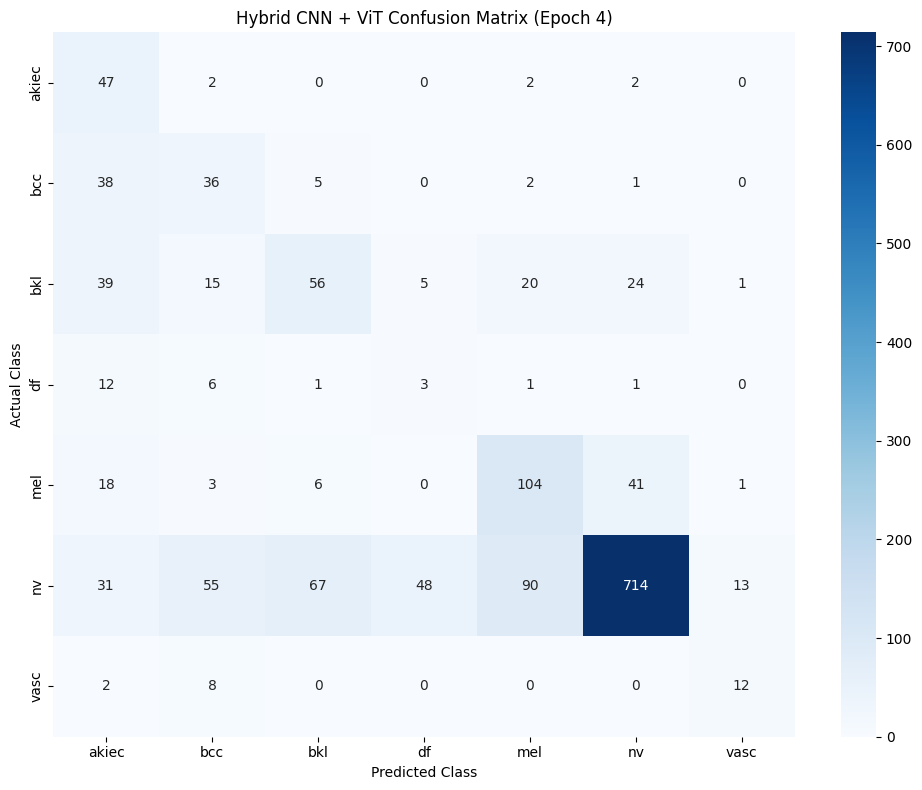


Classification Report:
              precision    recall  f1-score   support

       akiec       0.25      0.89      0.39        53
         bcc       0.29      0.44      0.35        82
         bkl       0.41      0.35      0.38       160
          df       0.05      0.12      0.07        24
         mel       0.47      0.60      0.53       173
          nv       0.91      0.70      0.79      1018
        vasc       0.44      0.55      0.49        22

    accuracy                           0.63      1532
   macro avg       0.41      0.52      0.43      1532
weighted avg       0.73      0.63      0.67      1532

SUCCESS! Confusion matrix created and saved.


In [25]:
import torch
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import confusion_matrix, classification_report

# Use the best model from Epoch 4
model.eval()

all_labels = []
all_predictions = []

print("Generating confusion matrix...")

with torch.no_grad():
    for images, labels in val_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        all_labels.extend(labels.numpy())
        all_predictions.extend(predictions.cpu().numpy())

# Create confusion matrix
cm = confusion_matrix(
    all_labels,
    all_predictions,
    labels=list(range(7))
)

# Display confusion matrix
plt.figure(figsize=(10, 8))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=class_names,
    yticklabels=class_names
)

plt.title("Hybrid CNN + ViT Confusion Matrix (Epoch 4)")
plt.xlabel("Predicted Class")
plt.ylabel("Actual Class")
plt.tight_layout()

# Save the figure
plt.savefig(
    "/kaggle/working/hybrid_cnn_vit_confusion_matrix.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("\nClassification Report:")
print(
    classification_report(
        all_labels,
        all_predictions,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    )
)

print("SUCCESS! Confusion matrix created and saved.")

In [26]:
import torch
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    balanced_accuracy_score,
    classification_report
)

# Evaluate the best model on the test dataset
model.eval()

test_labels = []
test_predictions = []

print("Starting final test evaluation...")

with torch.no_grad():
    for images, labels in test_loader:

        images = images.to(device)

        outputs = model(images)
        predictions = outputs.argmax(dim=1)

        test_labels.extend(labels.numpy())
        test_predictions.extend(predictions.cpu().numpy())

test_accuracy = accuracy_score(test_labels, test_predictions)

test_macro_f1 = f1_score(
    test_labels,
    test_predictions,
    average="macro",
    zero_division=0
)

test_balanced_accuracy = balanced_accuracy_score(
    test_labels,
    test_predictions
)

print("\nFINAL TEST RESULTS")
print("-----------------------------")
print(f"Test Accuracy: {test_accuracy * 100:.2f}%")
print(f"Test Macro F1: {test_macro_f1:.4f}")
print(f"Test Balanced Accuracy: {test_balanced_accuracy * 100:.2f}%")

print("\nClassification Report:")
print(
    classification_report(
        test_labels,
        test_predictions,
        labels=list(range(7)),
        target_names=class_names,
        zero_division=0
    )
)

print("\nSUCCESS! Final test evaluation completed.")

Starting final test evaluation...

FINAL TEST RESULTS
-----------------------------
Test Accuracy: 64.38%
Test Macro F1: 0.4435
Test Balanced Accuracy: 51.46%

Classification Report:
              precision    recall  f1-score   support

       akiec       0.22      0.67      0.33        52
         bcc       0.37      0.48      0.41        71
         bkl       0.43      0.36      0.39       167
          df       0.09      0.20      0.12        20
         mel       0.39      0.54      0.46       167
          nv       0.91      0.73      0.81      1004
        vasc       0.57      0.62      0.59        21

    accuracy                           0.64      1502
   macro avg       0.42      0.51      0.44      1502
weighted avg       0.73      0.64      0.67      1502


SUCCESS! Final test evaluation completed.


In [27]:
import pandas as pd

final_results = pd.DataFrame({
    "Metric": [
        "Test Accuracy",
        "Test Macro F1",
        "Test Balanced Accuracy",
        "Best Epoch",
        "Test Images"
    ],
    "Value": [
        64.38,
        0.4435,
        51.46,
        4,
        1502
    ]
})

final_results.to_csv(
    "/kaggle/working/hybrid_cnn_vit_final_test_results.csv",
    index=False
)

print(final_results)

print("\nSUCCESS! Final test results saved.")

                   Metric      Value
0           Test Accuracy    64.3800
1           Test Macro F1     0.4435
2  Test Balanced Accuracy    51.4600
3              Best Epoch     4.0000
4             Test Images  1502.0000

SUCCESS! Final test results saved.
